# Region of Interest from the Vanishing Point

A camera mounted in a car sees the whole scene, but lane detection only needs the road ahead. A **region of interest (ROI)** is the part of the image that is kept for the next step. Everything outside it is removed.

A fixed, hand-drawn polygon only works for one camera position. This notebook builds the ROI **from the image itself**:
1. Find the lane markings with Canny edges and the Hough transform.
2. Split them into left and right lines by their slope.
3. Fit a line through each side and intersect them. The intersection is the **vanishing point**, where parallel lane lines meet on the horizon.
4. Build a trapezoid from the vanishing point down to the bottom of the image.
5. Apply the mask, and fall back to a fixed polygon when the lines cannot be found.
6. Save all results to `output/`.

Under a pinhole camera, parallel lane lines meet at one point on the horizon, so the vanishing point marks where the road disappears. The ROI is therefore anchored to the image geometry instead of to a hand-picked position.

## 1. Imports

- `cv2` (OpenCV): image I/O, edge detection, Hough transform and polygon filling
- `matplotlib`: displaying images
- `numpy`: least-squares fitting and array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. Configuration

- `INPUT_PATH`: the road photo. It is the same photo as in the lane detection notebooks.
- `SEARCH_POLYGON`: the area where lane markings are searched for. It is wider than the final ROI and covers only the lower part of the image, so that sky, trees and signs are ignored.
- `CANNY_THRESHOLDS`, `HOUGH_*`: the edge and line detection settings. They were tuned on this photo.
- `MIN_SLOPE`: lines flatter than this are not lane markings and are discarded.
- `TOP_MARGIN`: the ROI stops this many pixels below the vanishing point.
- `FALLBACK_ROI`: a fixed polygon, used when the lines cannot be found.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("image_lane_c.jpg")
OUTPUT_DIR = Path("output")

SEARCH_POLYGON = np.array([[(0, 540), (300, 300), (660, 300), (960, 540)]], dtype=np.int32)

CANNY_THRESHOLDS = (50, 150)
HOUGH_THRESHOLD = 40
HOUGH_MIN_LENGTH = 40
HOUGH_MAX_GAP = 150
MIN_SLOPE = 0.4

TOP_MARGIN = 15

FALLBACK_ROI = np.array([[(0, 540), (400, 335), (560, 335), (960, 540)]], dtype=np.int32)

## 3. Load the image and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `roi_mask` returns a single-channel mask with 255 inside a polygon.
- `draw_polygon` draws a polygon outline and its corners on a copy of the image.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def roi_mask(shape: tuple[int, ...], polygon: np.ndarray) -> np.ndarray:
    """Single-channel mask: 255 inside the polygon, 0 outside."""
    mask = np.zeros(shape[:2], dtype=np.uint8)
    return cv2.fillPoly(mask, polygon, 255)


def draw_polygon(img: np.ndarray, polygon: np.ndarray) -> np.ndarray:
    """Return a copy of the image with the polygon outline and corners drawn in red."""
    out = img.copy()
    cv2.polylines(out, polygon, isClosed=True, color=(0, 0, 255), thickness=3)
    for x, y in polygon[0]:
        cv2.circle(out, (int(x), int(y)), 6, (0, 0, 255), thickness=-1)
    return out


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Image size (height, width): 540, 960


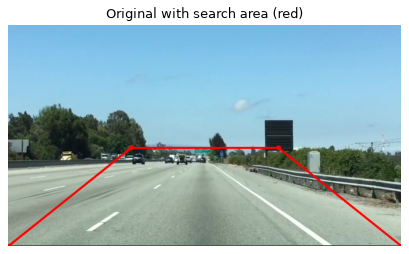

In [4]:
image = load_image(INPUT_PATH)
height, width = image.shape[:2]
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print(f"Image size (height, width): {height}, {width}")

show_images({"Original with search area (red)": draw_polygon(image, SEARCH_POLYGON)})

## 4. Find the lane line segments

The image is blurred, and the Canny edge detector finds the edges inside the search area. `cv2.HoughLinesP` then finds straight line segments among those edges.

Each segment is sorted by its slope in image coordinates, where `y` grows downwards:
- A **negative** slope is a line that rises to the left: the left lane.
- A **positive** slope is a line that rises to the right: the right lane.
- Lines with a slope smaller than `MIN_SLOPE` in absolute value are almost horizontal and are discarded. They are usually shadows, cars or the horizon, not lane markings.

Left segments: 2, right segments: 5


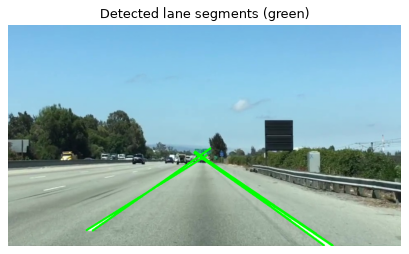

In [5]:
def detect_lane_segments(gray_img: np.ndarray, search: np.ndarray):
    """Return (left, right) lists of line segments (x1, y1, x2, y2) that look like lane markings."""
    blurred = cv2.GaussianBlur(gray_img, (5, 5), 0)
    edges = cv2.Canny(blurred, *CANNY_THRESHOLDS)
    edges = cv2.bitwise_and(edges, roi_mask(gray_img.shape, search))

    segments = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=HOUGH_THRESHOLD,
                               minLineLength=HOUGH_MIN_LENGTH, maxLineGap=HOUGH_MAX_GAP)
    left, right = [], []
    if segments is None:
        return left, right
    for x1, y1, x2, y2 in segments.reshape(-1, 4):
        if x2 == x1:
            continue  # exactly vertical: no slope to compare
        slope = (y2 - y1) / (x2 - x1)
        if abs(slope) < MIN_SLOPE:
            continue
        (left if slope < 0 else right).append((int(x1), int(y1), int(x2), int(y2)))
    return left, right


left_segments, right_segments = detect_lane_segments(gray, SEARCH_POLYGON)
print(f"Left segments: {len(left_segments)}, right segments: {len(right_segments)}")

segment_view = image.copy()
for x1, y1, x2, y2 in left_segments + right_segments:
    cv2.line(segment_view, (x1, y1), (x2, y2), (0, 255, 0), 3)
show_images({"Detected lane segments (green)": segment_view})

## 5. Fit a line to each side and find the vanishing point

Each side is fitted with one straight line by least squares. The fit is written as $x = k\,y + c$, which is stable for lane lines that are close to vertical in the image. Using all the endpoints of the segments on one side gives one line for the left lane and one for the right lane.

The two lines meet at the **vanishing point**:

$$k_L\,y + c_L = k_R\,y + c_R \quad\Rightarrow\quad y_{vp} = \frac{c_R - c_L}{k_L - k_R}, \qquad x_{vp} = k_L\,y_{vp} + c_L$$

If the lines are parallel, $k_L = k_R$ and there is no vanishing point, so the function returns `None`. The same happens if the point lies below the bottom of the road area.

In [6]:
def fit_x_of_y(segments: list[tuple[int, int, int, int]]) -> tuple[float, float]:
    """Least-squares line x = k * y + c through all the endpoints of the segments."""
    pts = np.array([(x, y) for x1, y1, x2, y2 in segments for x, y in ((x1, y1), (x2, y2))], dtype=float)
    A = np.column_stack([pts[:, 1], np.ones(len(pts))])
    k, c = np.linalg.lstsq(A, pts[:, 0], rcond=None)[0]
    return k, c


def vanishing_point(left_fit: tuple[float, float], right_fit: tuple[float, float]):
    """Intersection of the two fitted lines, or None if they are parallel or meet below the image."""
    kl, cl = left_fit
    kr, cr = right_fit
    if abs(kl - kr) < 1e-6:
        return None
    y = (cr - cl) / (kl - kr)
    x = kl * y + cl
    if not (0 < y < height):
        return None
    return x, y


if left_segments and right_segments:
    left_fit = fit_x_of_y(left_segments)
    right_fit = fit_x_of_y(right_segments)
    vp = vanishing_point(left_fit, right_fit)
    print(f"Vanishing point: x={vp[0]:.0f}, y={vp[1]:.0f}" if vp else "No valid vanishing point")
else:
    left_fit = right_fit = vp = None
    print("Lane lines not found on both sides")

Vanishing point: x=471, y=322


## 6. Build the ROI from the vanishing point

The ROI is a trapezoid. Its bottom edge is the bottom of the image, and its top edge lies `TOP_MARGIN` pixels below the vanishing point. Its sides follow the fitted lane lines, so the ROI is wide at the bottom and narrows towards the vanishing point.

The corners are clipped to the image, so that a line that runs past the edge of the photo does not produce a polygon outside the image.

If the lanes cannot be found, the fixed `FALLBACK_ROI` is used and the notebook says so.

ROI source: vanishing point
ROI corners (bottom-left, top-left, top-right, bottom-right): [[140, 539], [449, 336], [491, 336], [787, 539]]


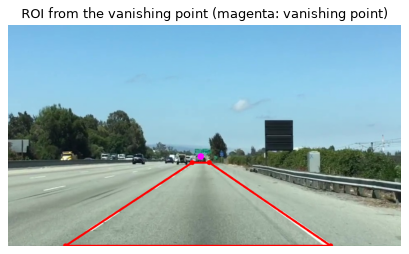

In [7]:
def roi_from_vanishing_point(left: tuple[float, float], right: tuple[float, float], vp_y: float):
    """Trapezoid from the bottom of the image up to just below the vanishing point."""
    top = int(vp_y) + TOP_MARGIN
    x_left = lambda y: left[0] * y + left[1]
    x_right = lambda y: right[0] * y + right[1]
    corners = [(x_left(height), height), (x_left(top), top), (x_right(top), top), (x_right(height), height)]
    clipped = [(int(np.clip(x, 0, width - 1)), int(np.clip(y, 0, height - 1))) for x, y in corners]
    return np.array([clipped], dtype=np.int32)


if vp is not None:
    roi = roi_from_vanishing_point(left_fit, right_fit, vp[1])
    source = "vanishing point"
else:
    roi = FALLBACK_ROI
    source = "fallback polygon"
print(f"ROI source: {source}")
print("ROI corners (bottom-left, top-left, top-right, bottom-right):", roi[0].tolist())

vp_view = draw_polygon(image, roi)
if vp is not None:
    cv2.circle(vp_view, (int(vp[0]), int(vp[1])), 8, (255, 0, 255), thickness=-1)
show_images({"ROI from the vanishing point (magenta: vanishing point)": vp_view})

## 7. Apply the ROI

The mask is built from the ROI, and `cv2.bitwise_and` keeps only the pixels inside it, as in the earlier notebook. The same mask is applied to the grayscale and the colour image.

Share of the image kept by the ROI: 13.6%


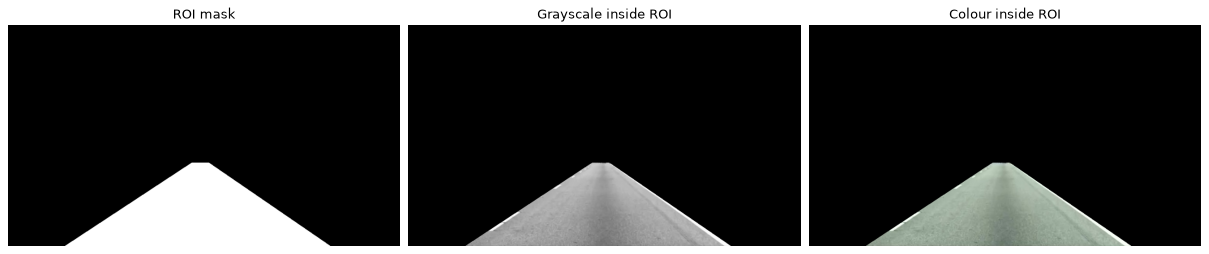

In [8]:
mask = roi_mask(gray.shape, roi)
masked_gray = cv2.bitwise_and(gray, mask)
masked_colour = cv2.bitwise_and(image, image, mask=mask)

print(f"Share of the image kept by the ROI: {(mask > 0).mean():.1%}")
show_images({"ROI mask": mask, "Grayscale inside ROI": masked_gray, "Colour inside ROI": masked_colour}, cols=3)

## 8. Compare with the fixed polygon

The fixed polygon from the previous notebook was chosen by eye for this photo. The comparison shows that the vanishing-point ROI reaches the same lane lines without any hand-picked corners.

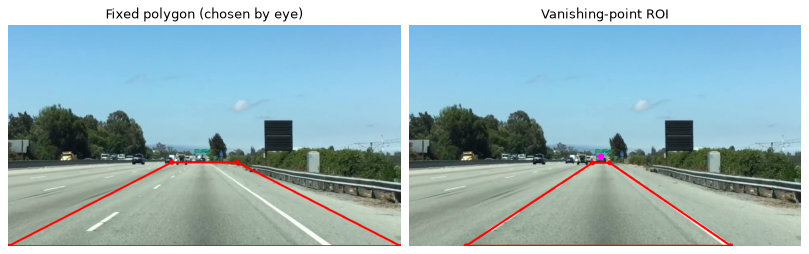

In [9]:
fixed_view = draw_polygon(image, FALLBACK_ROI)
show_images({
    "Fixed polygon (chosen by eye)": fixed_view,
    "Vanishing-point ROI": vp_view,
}, cols=2)

## 9. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [10]:
stem = INPUT_PATH.stem
outputs = {
    "lane_segments": segment_view,
    "roi_outline": vp_view,
    "roi_mask": mask,
    "roi_gray": masked_gray,
    "roi_colour": masked_colour,
    "roi_outline_fixed": fixed_view,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/image_lane_c_lane_segments.jpg
Saved output/image_lane_c_roi_outline.jpg
Saved output/image_lane_c_roi_mask.jpg
Saved output/image_lane_c_roi_gray.jpg
Saved output/image_lane_c_roi_colour.jpg
Saved output/image_lane_c_roi_outline_fixed.jpg


## 10. Conclusion

- The **vanishing point** is where the lane lines meet. It gives the top of the road ROI, and the ROI follows the lane lines instead of a fixed polygon.
- The method uses only classical steps: Canny edges, the Hough transform, least-squares fitting and a polygon mask. It is fast and easy to inspect, and each step can be checked on the image.
- It has limits. It needs straight lane lines visible on both sides. Curves, worn or missing markings, and a car in front can make the fit wrong. The fallback and the overlays help to spot these cases.
- Current lane detection systems often go further. Learned models such as SCNN, LaneNet, UFLD and CLRNet find the lanes directly from the whole image, and tracking uses the previous frame to update the ROI. Those methods need a trained network and are beyond this notebook.